## **Visualizaciones**

Este notebook reúne los gráficos del análisis, organizados por hipótesis. 

Se usan los datasets sintéticos de Kaggle de empleados (`ai_productivity_features.csv` y `ai_productivity_targets.csv`, 4.500 personas) y de estudiantes (`ai_student_impact_dataset.csv`, 50.000 estudiantes).

Cada gráfico lleva encima qué muestra y por qué se eligió y debajo lo que se observa. Las imágenes se guardan en `../img/` y se usan en la presentación.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

etiquetas = ["Bajo", "Medio-bajo", "Medio-alto", "Alto"]

# Empleados
df_features = pd.read_csv("../data/ai_productivity_features.csv")
df_targets = pd.read_csv("../data/ai_productivity_targets.csv")
df_empleados = pd.merge(df_features, df_targets, on="Employee_ID")

columns_orden = ["productivity_score", "burnout_risk_score", "burnout_risk_level"]
columns_resto = [c for c in df_empleados.columns if c not in columns_orden]

df_empleados_2 = df_empleados[columns_resto + columns_orden]

df_empleados_2["tramo_ia"] = pd.qcut(df_empleados["ai_tool_usage_hours_per_week"], q=4, labels=etiquetas)

# Estudiantes
df_estudiantes = pd.read_csv("../data/ai_student_impact_dataset.csv")
df_estudiantes["tramo_ia"] = pd.qcut(df_estudiantes["Weekly_GenAI_Hours"], q=4, labels=etiquetas)
df_estudiantes["mejora_nota"] = df_estudiantes["Post_Semester_GPA"] - df_estudiantes["Pre_Semester_GPA"]

##### Cómo se definen los tramos de horas de IA

Para comparar grupos, en cada dataset se divide a las personas en 4 tramos según sus horas semanales de IA, con grupos de tamaño parecido (cuartiles, con `pd.qcut`). Como el uso de IA es distinto en empleados y estudiantes, los cortes también lo son:

| Tramo | Empleados (h/semana) | Estudiantes (h/semana) |
|---|---|---|
| Bajo | hasta 6,0 | hasta 2,4 |
| Medio-bajo | de 6,0 a 9,7 | de 2,4 a 5,8 |
| Medio-alto | de 9,7 a 14,3 | de 5,8 a 11,7 |
| Alto | más de 14,3 | más de 11,7 |

Los grupos no son exactamente iguales (de 1.103 a 1.144 empleados por tramo) porque hay personas con las mismas horas justo en los cortes y `qcut` no puede separarlas.

#### Hipótesis 1: Quien usa más IA es más productivo

##### Gráfico 1. Productividad y errores por tramo de horas de IA

**Qué muestra:** Dos gráficos de barras juntos con las medias de cada tramo. Las barras empiezan en 0, así que no se exageran las diferencias.

**Por qué estas variables:** Las horas de IA frente a la productividad responden a la hipótesis 1 y los errores responden al "¿a qué precio?".

**Por qué barras desde 0, en dos paneles:** Se comparan 4 grupos con un valor cada uno y hay dos paneles porque las unidades son distintas (puntos y %).

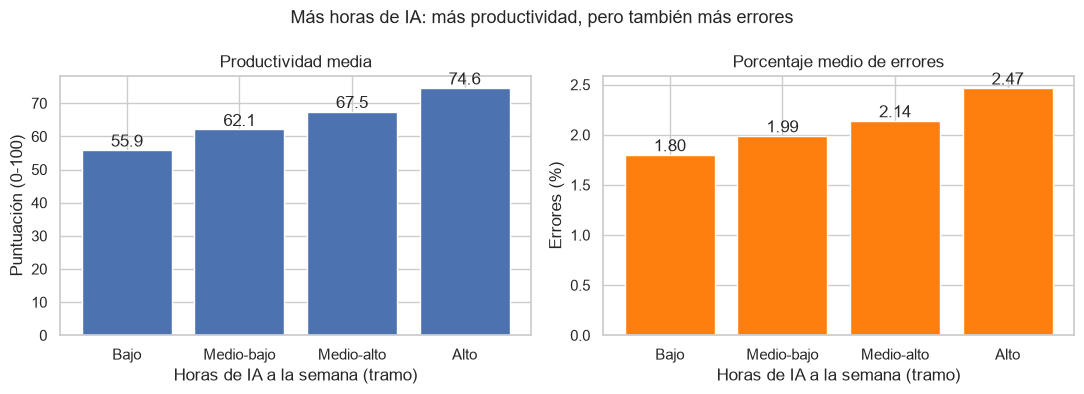

In [2]:
medias = df_empleados_2.groupby("tramo_ia", observed=True)[["productivity_score", "error_rate_percent"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(medias.index.astype(str), medias["productivity_score"])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f")
axes[0].set_title("Productividad media")
axes[0].set_ylabel("Puntuación (0-100)")

axes[1].bar(medias.index.astype(str), medias["error_rate_percent"], color="tab:orange")
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
axes[1].set_title("Porcentaje medio de errores")
axes[1].set_ylabel("Errores (%)")

for ax in axes:
    ax.set_xlabel("Horas de IA a la semana (tramo)")

fig.suptitle("Más horas de IA: más productividad, pero también más errores", fontsize=13)
fig.tight_layout()
fig.savefig("../img/h1_productividad_errores.png", dpi=150, bbox_inches="tight")
plt.show()

- Cada barra es la media de unas 1.125 personas.
- La productividad pasa de 55,9 (tramo Bajo, hasta 6 h) a 74,6 (tramo Alto, más de 14,3 h): 18,7 puntos más.
- Los errores pasan de 1,80% a 2,47%: 0,67 puntos más, un 37% más.

##### Gráfico 1b. Productividad por puesto y tramo de horas de IA

**Qué muestra:**
- La productividad media de cada puesto de trabajo en cada tramo de horas de IA.
- Cada celda es la media de un puesto en un tramo y cuanto más oscuro el azul, mayor la productividad.
- Las celdas vacías son combinaciones con menos de 30 personas (Manager-Alto, Designer-Alto y Writer-Bajo) que se ocultan porque una media de tan pocos casos no es fiable.

**Por qué este gráfico:** El gráfico 1 mezcla todos los puestos. Este comprueba que la relación entre horas de IA y productividad no se debe solo a qué puestos usan más IA, sino que aparece dentro de cada puesto.

**Por qué un mapa de calor:** Cruza dos categorías (puesto y tramo) con un valor numérico en cada celda. Leyendo cada fila de izquierda a derecha se ve si la productividad sube con las horas de IA y comparando filas, si el patrón se repite en todos los puestos. Los valores van anotados porque el color solo da una idea aproximada.

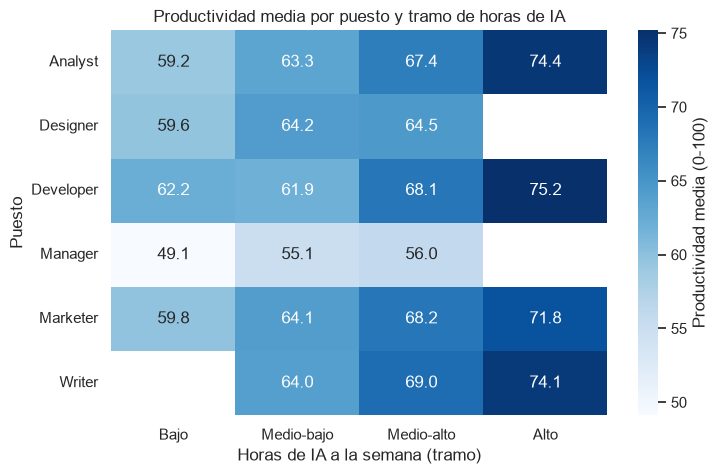

In [3]:
pivot = df_empleados_2.pivot_table(index="job_role", columns="tramo_ia",
                                   values="productivity_score", aggfunc="mean", observed=True)
conteo = pd.crosstab(df_empleados_2["job_role"], df_empleados_2["tramo_ia"]).reindex_like(pivot)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, mask=conteo < 30, annot=True, fmt=".1f", cmap="Blues",
            cbar_kws={"label": "Productividad media (0-100)"}, ax=ax)
ax.set_xlabel("Horas de IA a la semana (tramo)")
ax.set_ylabel("Puesto")
ax.set_title("Productividad media por puesto y tramo de horas de IA")

ax.tick_params(axis="y", rotation=0)
ax.grid(False)

fig.savefig("../img/h1_heatmap_puesto.png", dpi=150, bbox_inches="tight")
plt.show()

- En todos los puestos la productividad es mayor en el tramo más alto con datos que en el más bajo.
- En Analyst pasa de 59,2 a 74,4 (+15,2), en Developer de 62,2 a 75,2 (+13,0) y en Marketer de 59,8 a 71,8 (+12,0). En Writer sube de 64,0 a 74,1 entre Medio-bajo y Alto.
- La subida es casi continua. La única excepción es Developer entre Bajo y Medio-bajo (62,2 a 61,9), una diferencia de 0,3 que no es relevante (en Bajo hay solo 31 developers).
- Manager es el puesto con menor productividad en todos los tramos (49,1 a 56,0). Parece un efecto del puesto más que de la IA, así que la comparación válida es dentro de cada fila.

**Conclusión:**
- La relación entre más horas de IA y más productividad aparece dentro de cada puesto, no solo en el conjunto.
- Es una asociación: no prueba que la IA cause la mejora.

#### Hipótesis 2: El uso excesivo de la IA tiene efectos negativos en el bienestar

##### Gráfico 2. Empleados: ¿IA o plazos?

**Qué muestra:** El burnout medio por tramo de IA (a la izquierda) y por presión de plazos (a la derecha), con la misma escala (0-10). Así se ve a simple vista que el primero casi no cambia y el segundo sí.

**Por qué estas variables:** Se usa `burnout_risk_score` (numérico) y no el nivel, porque la etiqueta tiene al 73% en "High" y no distingue. La IA se compara con otro factor, la presión de plazos, para ver cuál pesa más.

**Por qué dos paneles con el mismo eje:** Para comparar de un vistazo en la misma escala.

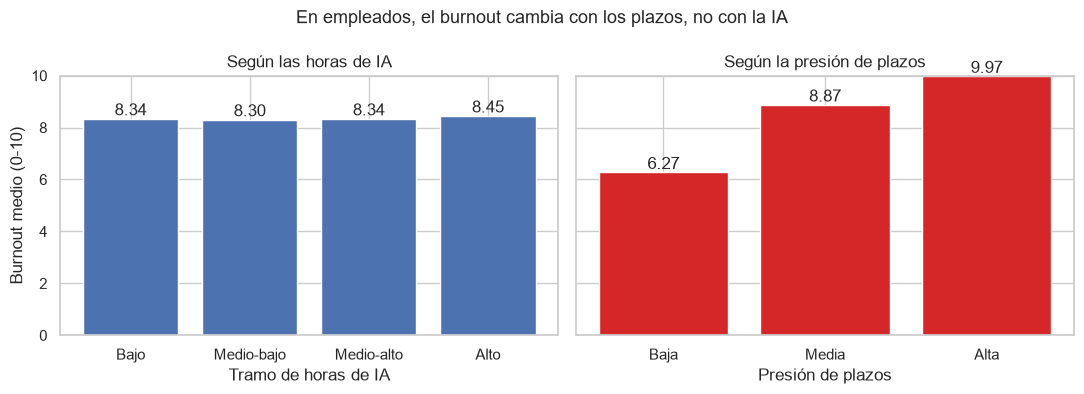

In [4]:
por_tramo = df_empleados_2.groupby("tramo_ia", observed=True)["burnout_risk_score"].mean()
# reindex pone la presión en orden lógico (Low, Medium, High); por defecto saldría en orden alfabético
por_presion = df_empleados_2.groupby("deadline_pressure_level")["burnout_risk_score"].mean().reindex(["Low", "Medium", "High"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

axes[0].bar(por_tramo.index.astype(str), por_tramo.values)
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[0].set_title("Según las horas de IA")
axes[0].set_xlabel("Tramo de horas de IA")
axes[0].set_ylabel("Burnout medio (0-10)")

axes[1].bar(["Baja", "Media", "Alta"], por_presion.values, color="tab:red")
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
axes[1].set_title("Según la presión de plazos")
axes[1].set_xlabel("Presión de plazos")

axes[0].set_ylim(0, 10)
fig.suptitle("En empleados, el burnout cambia con los plazos, no con la IA", fontsize=13)
fig.tight_layout()
fig.savefig("../img/h2_burnout_empleados.png", dpi=150, bbox_inches="tight")
plt.show()

El burnout medio es casi igual en los cuatro tramos de IA (8,34; 8,30; 8,34; 8,45), pero cambia con la presión de plazos: 6,27 con presión baja, 8,87 media y 9,97 alta. 

En empleados la IA no se asocia a más burnout, pero los plazos sí.

##### Gráfico 3. Estudiantes: burnout por tramo de horas de IA

**Qué muestra:** Una barra por tramo, dividida en el porcentaje de estudiantes con burnout bajo, medio y alto. Cada barra suma 100%.

**Por qué barras apiladas al 100%:** Muestran cómo se reparte cada grupo entre burnout bajo, medio y alto. Los colores verde/amarillo/rojo se entienden solos.

**Por qué este gráfico:** En estudiantes el burnout no es una puntuación sino una categoría (bajo, medio o alto), así que se compara qué porcentaje de cada tramo de horas de IA está en cada nivel. Responde a la hipótesis 2 con este dataset: ¿el uso excesivo (tramo Alto) se asocia con más burnout?

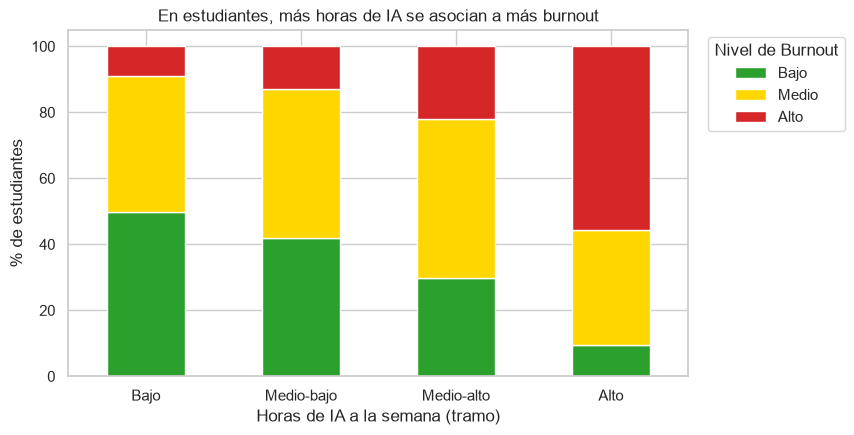

In [5]:
burnout = pd.crosstab(df_estudiantes["tramo_ia"], df_estudiantes["Burnout_Risk_Level"], normalize="index") * 100
burnout = burnout[["Low", "Medium", "High"]]

ax = burnout.plot(kind="bar", stacked=True, figsize=(8, 4.5),
                  color=["tab:green", "gold", "tab:red"])
ax.set_xlabel("Horas de IA a la semana (tramo)")
ax.set_ylabel("% de estudiantes")
ax.set_title("En estudiantes, más horas de IA se asocian a más burnout")
ax.legend(["Bajo", "Medio", "Alto"], title="Nivel de Burnout", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)
ax.figure.savefig("../img/h2_burnout_estudiantes.png", dpi=150, bbox_inches="tight")
plt.show()

- Cada barra es el 100% de los estudiantes de un tramo.
- El burnout alto pasa de 9,1% (Bajo, hasta 2,4 h) a 12,9%, 22,2% y 55,8% (Alto, más de 11,7 h).
- Sube poco a poco y da el gran salto en el último tramo.

#### Hipótesis 3: Los estudiantes que usan más IA sacan mejores notas, pero retienen menos lo aprendido

##### Gráfico 4. Mejora de nota y retención por tramo de horas de IA

**Qué muestra:** Dos gráficos de líneas, uno por cada medida, con el valor anotado sobre cada punto. El eje vertical no empieza en 0 y las diferencias son pequeñas, así que conviene leer los valores y no solo la forma de la línea.

**Por qué líneas con eje recortado:** Las diferencias de nota son muy pequeñas y con barras desde 0 apenas se verían. Por eso se anota cada valor.

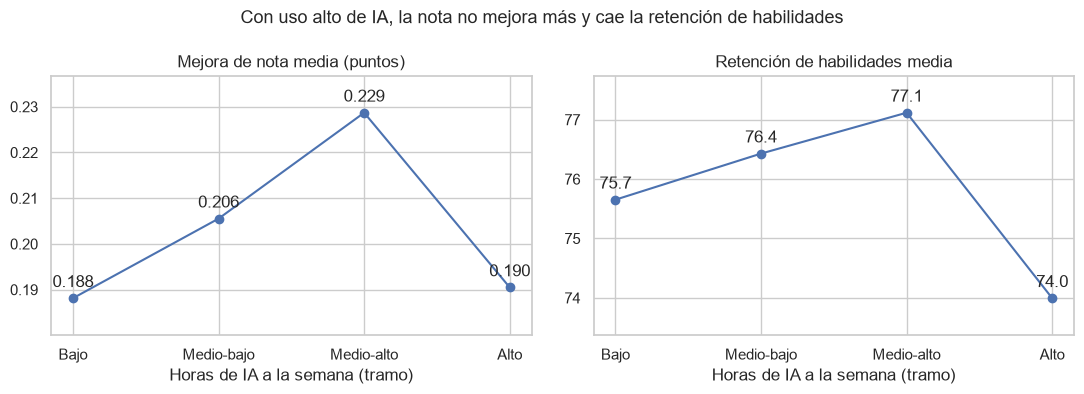

In [6]:
medias_estudiantes = df_estudiantes.groupby("tramo_ia", observed=True)[["mejora_nota", "Skill_Retention_Score"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# un bucle para no repetir el código de los dos paneles
for ax, col, titulo, fmt in [
    (axes[0], "mejora_nota", "Mejora de nota media (puntos)", "{:.3f}"),
    (axes[1], "Skill_Retention_Score", "Retención de habilidades media", "{:.1f}"),
]:
    x = medias_estudiantes.index.astype(str)
    y = medias_estudiantes[col]
    ax.plot(x, y, marker="o")
    for xi, yi in zip(x, y):
        ax.annotate(fmt.format(yi), (xi, yi), textcoords="offset points", xytext=(0, 8), ha="center")
    ax.set_title(titulo)
    ax.set_xlabel("Horas de IA a la semana (tramo)")
    ax.margins(y=0.2)

fig.suptitle("Con uso alto de IA, la nota no mejora más y cae la retención de habilidades", fontsize=13)
fig.tight_layout()
fig.savefig("../img/h3_mejora_retencion.png", dpi=150, bbox_inches="tight")
plt.show()

- La mejora de nota apenas varía entre tramos (entre 0,19 y 0,23 puntos de GPA): es algo mayor en el tramo Medio-alto (0,229 puntos, 5,8-11,7 h) que en Bajo (0,188), y en Alto vuelve a 0,190.
- La retención de habilidades baja en el tramo Alto: 74,0 frente a 77,1 en Medio-alto. Es la diferencia más clara de este gráfico.

##### Gráfico 4b. Mejora de nota según el tipo de uso de la IA

**Qué muestra:** La mejora media de nota (nota final menos nota inicial) de los estudiantes según para qué usan principalmente la IA. Hay cinco tipos de uso y cada barra es la media de un grupo. Están ordenadas de más mejora (arriba) a menos (abajo).

**Por qué este gráfico:** los gráficos anteriores miden cuánto se usa la IA; este mide cómo se usa. Así se comprueba si el tipo de uso importa, además de las horas.

**Por qué barras horizontales:** Son cinco categorías con nombres largos, que se leen mejor en horizontal. Las barras empiezan en 0 y llevan el valor escrito, así que se comparan directamente.

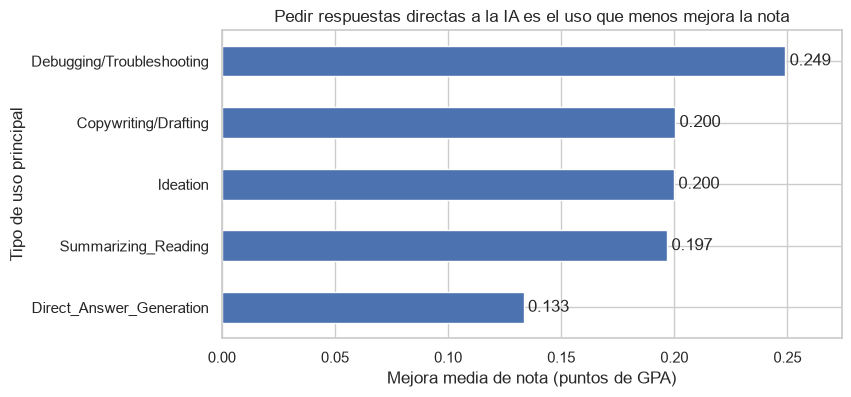

In [7]:
mejora_uso = df_estudiantes.groupby("Primary_Use_Case")["mejora_nota"].mean().sort_values()

ax = mejora_uso.plot(kind="barh", figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.margins(x=0.1)
ax.set_xlabel("Mejora media de nota (puntos de GPA)")
ax.set_ylabel("Tipo de uso principal")
ax.set_title("Pedir respuestas directas a la IA es el uso que menos mejora la nota")
ax.figure.savefig("../img/h3_mejora_por_uso.png", dpi=150, bbox_inches="tight")
plt.show()

- Pedir respuestas directas a la IA es el uso que menos mejora la nota (0,133 puntos) y depurar código el que más (0,249): casi el doble. Los otros tres usos quedan entre ambos.

- Todos los grupos son grandes (de 6.340 a 12.295 estudiantes), así que la diferencia no se explica por un grupo pequeño.

- Es una asociación, no prueba que el tipo de uso cause la mejora. Puede que quienes eligen cada uso sean estudiantes distintos entre sí.

Conclusión: 
- El cómo importa, no solo el cuánto. 
- Usar la IA para obtener la respuesta se asocia a menos mejora que usarla para tareas donde hay que trabajar con ella, como depurar.